In [348]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

class StructuredGraphBuilder:
    def __init__(self):
        self.G = nx.DiGraph()
        self.pos = {}

    def return_graph(self):
        return self.G, self.pos

    def add_entity(self, node_id, label=None, pos=(0, 0)):
        self.G.add_node(node_id, label=label or node_id, node_type="entity")
        self.pos[node_id] = pos

    def add_property(self, target_node_id, prop_name, prop_value, prop_pos=None, val_pos=None ):
        """
        Attaches a property to any existing node.

        [Target Node] --- [property] ---> [value]

        If prop_pos is not supplied, it is placed halfway between
        the target node and the value node.
        """
        prop_id = f"{target_node_id}_{prop_name}"
        val_id = f"{target_node_id}_{prop_name}_{prop_value}"
        self.G.add_node( prop_id, label=prop_name, node_type="relation" )
        self.G.add_node( val_id, label=str(prop_value), node_type="value" )

        # Value position must be supplied because it determines
        # the direction/extent of the property.
        if val_pos is None:
            raise ValueError( "val_pos must be specified when adding a property." )
        # Default property position = midpoint of target and value
        if prop_pos is None:
            target_pos = self.pos[target_node_id]
            prop_pos = ( (3*target_pos[0] + 2*val_pos[0])/5, (3*target_pos[1] + 2*val_pos[1])/5 )

        self.pos[prop_id] = prop_pos
        self.pos[val_id] = val_pos

        self.G.add_edge(target_node_id, prop_id)
        self.G.add_edge(prop_id, val_id)

    def add_reified_edge( self, source, rel_name, target, rel_pos=None, meta_nodes=None ):
        """
        Creates a reified relation:

        [source] ---> [relation] ---> [target]

        If rel_pos is not supplied, the relation is placed
        halfway between source and target.
        """

        source_pos = self.pos[source]
        target_pos = self.pos[target]
        # Default relation position = midpoint
        if rel_pos is None:
            rel_pos = ( (3*source_pos[0] + 2*target_pos[0])/5, (3*source_pos[1] + 2*target_pos[1])/5 )

        rel_id = f"{source}_{rel_name}_{target}"
        self.G.add_node( rel_id, label=rel_name, node_type="relation" )
        self.pos[rel_id] = rel_pos
        self.G.add_edge(source, rel_id)
        self.G.add_edge(rel_id, target)

        if meta_nodes:
            for meta_rel_name, meta_source_id in meta_nodes:
                meta_rel_id = ( f"{meta_source_id}_{meta_rel_name}_{rel_id}" )
                mx = ( 2*self.pos[meta_source_id][0] + rel_pos[0] ) / 3
                my = ( 2*self.pos[meta_source_id][1] + rel_pos[1] ) / 3
                self.G.add_node( meta_rel_id, label=meta_rel_name, node_type="relation" )
                self.pos[meta_rel_id] = (mx, my)
                self.G.add_edge(meta_source_id, meta_rel_id)
                self.G.add_edge(meta_rel_id, rel_id)

        return rel_id

    def get_triples(self):
        G,_ = self.return_graph()
        triples = []
        for subject, relation in G.edges():
            if G.nodes[relation].get("node_type") != "relation":
                continue
            predicate = G.nodes[relation]["label"]
            for obj in G.successors(relation):
                if G.nodes[obj].get("node_type") == "value":
                    obj = G.nodes[obj]["label"]
                triples.append( (subject, predicate, obj) )
        return triples

    def draw(self, title=None, figsize=(10, 6), x_margin=0.5, y_margin=0.5):
        G, pos = self.return_graph()
        fig, ax = plt.subplots(figsize=figsize)

        STYLE_MAP = {
            "entity": dict( facecolor="skyblue", edgecolor="black", linewidth=1.5, weight="bold", color="black" ),
            "value": dict( facecolor="#e1f5fe", edgecolor="#0288d1", linewidth=1.2, weight="bold", color="#01579b" ),
            "relation": dict( facecolor="white", edgecolor="white", linewidth=0, weight="normal", color="red" ),
        }

        node_patches = {}
        text_objects = {}

        # Render nodes
        for n, (x, y) in pos.items():

            n_type = G.nodes[n].get("node_type", "entity")
            style = STYLE_MAP.get(n_type, STYLE_MAP["entity"])
            bbox_props = dict( boxstyle="round,pad=0.5,rounding_size=0.3", facecolor=style["facecolor"], edgecolor=style["edgecolor"], linewidth=style["linewidth"] )
            txt = ax.text( x, y, G.nodes[n]["label"], size=9, weight=style["weight"], color=style["color"], bbox=bbox_props, zorder=3, ha="center", va="center" )
            text_objects[n] = txt
            node_patches[n] = txt.get_bbox_patch()

        # Render edges
        for u, v in G.edges():

            u_type = G.nodes[u].get("node_type")
            v_type = G.nodes[v].get("node_type")
            arrowstyle = "-"

            if u_type == "relation" and v_type != "relation":
                arrowstyle = "-|>"

            arrow = mpatches.FancyArrowPatch(
                pos[u], pos[v], patchA=node_patches[u], patchB=node_patches[v],
                shrinkA=5, shrinkB=8, arrowstyle=arrowstyle,
                mutation_scale=15, color="black", alpha=0.6, zorder=3
            )
            ax.add_patch(arrow)

        # First-pass limits based on positions
        xs = [x for x, y in pos.values()]
        ys = [y for x, y in pos.values()]
        xmin, xmax = min(xs), max(xs)
        ymin, ymax = min(ys), max(ys)
        x_range = max(xmax - xmin, 1)
        y_range = max(ymax - ymin, 1)
        ax.set_xlim( xmin - x_range * 0.25, xmax + x_range * 0.25 )
        ax.set_ylim( ymin - y_range * 0.25, ymax + y_range * 0.25 )

        # Force Matplotlib to calculate text bounding boxes
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()

        # Determine actual rendered bounds
        data_boxes = []
        for txt in text_objects.values():
            bbox = txt.get_window_extent(renderer=renderer)
            # Convert display coordinates -> data coordinates
            corners = ax.transData.inverted().transform([ [bbox.x0, bbox.y0], [bbox.x1, bbox.y1] ])
            data_boxes.append(corners)

        # Actual object bounds
        actual_xmin = min(box[0][0] for box in data_boxes)
        actual_xmax = max(box[1][0] for box in data_boxes)
        actual_ymin = min(box[0][1] for box in data_boxes)
        actual_ymax = max(box[1][1] for box in data_boxes)

        # Add symmetric margins around ACTUAL rendered bounds
        ax.set_xlim( actual_xmin - x_margin, actual_xmax + x_margin )
        ax.set_ylim( actual_ymin - y_margin, actual_ymax + y_margin )

        # Formatting
        ax.axis("off")
        if title:
            ax.set_title(title, weight="bold")
        plt.show()

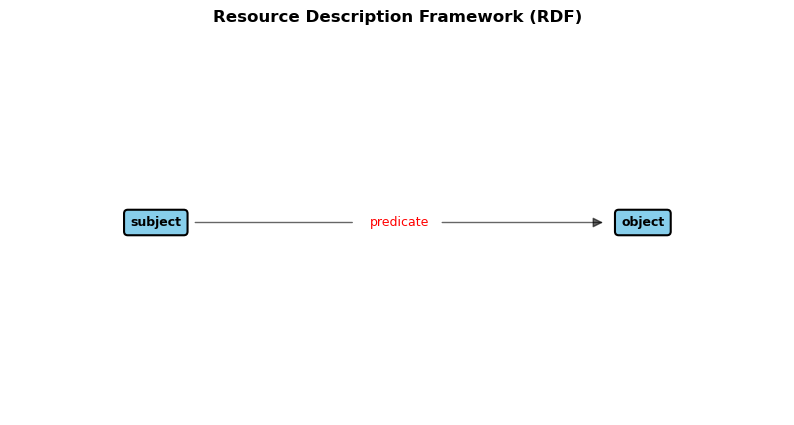

In [349]:
demo = StructuredGraphBuilder()
demo.add_entity("subject", pos=(-1, 0))
demo.add_entity("object", pos=(1, 0))
demo.add_reified_edge(source="subject", rel_name="predicate", target="object",rel_pos=(0,0))
demo.draw('Resource Description Framework (RDF)', figsize=(10, 5))

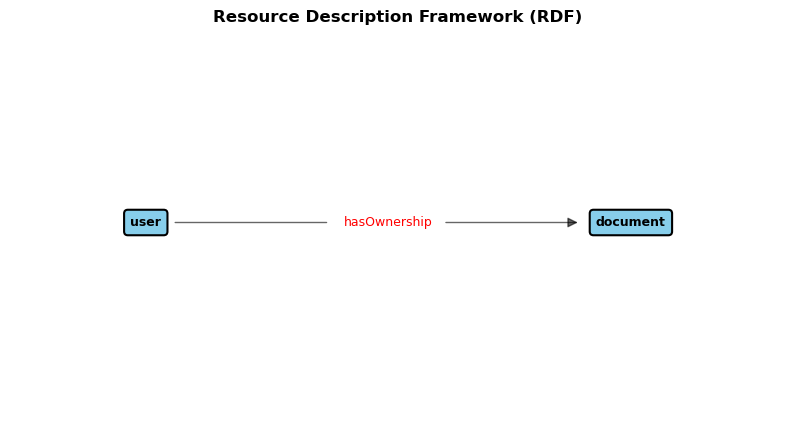

In [350]:
builder = StructuredGraphBuilder()

# Primary RDF
builder.add_entity("user", label="user", pos=(-1, 0))
builder.add_entity("document", label="document", pos=(1, 0))
hasOwnership_rel_id = builder.add_reified_edge(source="user", rel_name="hasOwnership", target="document", rel_pos=(0, 0),)
builder.draw('Resource Description Framework (RDF)', figsize=(10, 5))

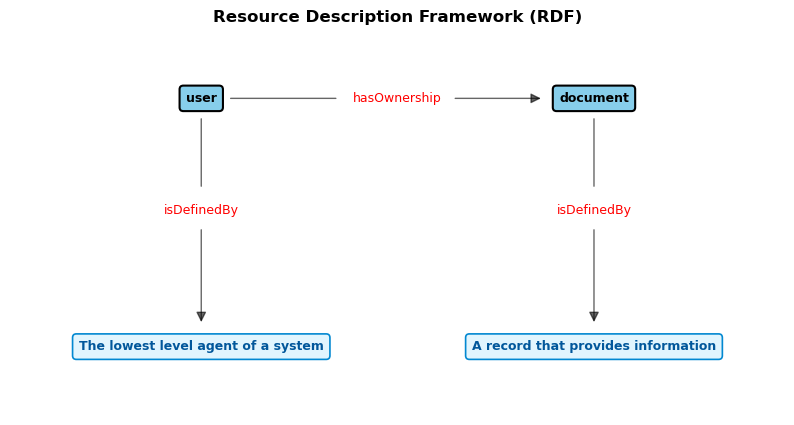

In [351]:
# Definition
builder.add_property(target_node_id="user", prop_name="isDefinedBy", prop_value="The lowest level agent of a system", prop_pos=(-1, -0.9), val_pos=(-1, -2))
builder.add_property(target_node_id="document", prop_name="isDefinedBy", prop_value="A record that provides information", prop_pos=(1, -0.9), val_pos=(1, -2))
builder.draw('Resource Description Framework (RDF)', figsize=(10, 5))

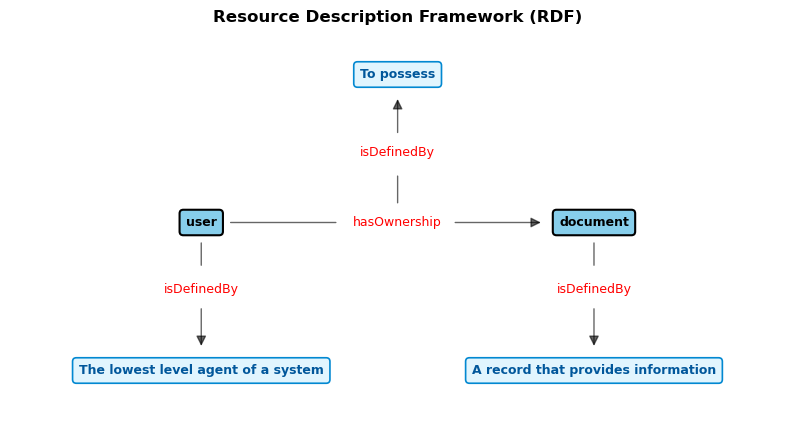

In [352]:
# Main Reified Edge Property
builder.add_property(target_node_id=hasOwnership_rel_id,prop_name="isDefinedBy",prop_value="To possess",prop_pos=(0, 0.95),val_pos=(0, 2))
builder.draw('Resource Description Framework (RDF)', figsize=(10, 5))

In [353]:
import pandas as pd, uuid6
df = pd.DataFrame({
    'object': ["user", "document", "hasOwnership"],
    'definition': ["The lowest level agent of a system", "A record that provides information", "To possess"],
    'semantic_uuid': [uuid6.uuid7(), uuid6.uuid7(), uuid6.uuid7(),],
    })

df.head()

,object,definition,semantic_uuid
0,user,The lowest level agent of a system,01a05512-c62c-741c-ba44-4dca7b493a5b
1,document,A record that provides information,01a05512-c62d-7697-815c-5fbd1a5f8955
2,hasOwnership,To possess,01a05512-c62e-784a-aac5-85651317b71d


In [354]:
df[['object', 'semantic_uuid']].head()

,object,semantic_uuid
0,user,01a05512-c62c-741c-ba44-4dca7b493a5b
1,document,01a05512-c62d-7697-815c-5fbd1a5f8955
2,hasOwnership,01a05512-c62e-784a-aac5-85651317b71d


In [355]:
df[['definition', 'semantic_uuid']].head()

,definition,semantic_uuid
0,The lowest level agent of a system,01a05512-c62c-741c-ba44-4dca7b493a5b
1,A record that provides information,01a05512-c62d-7697-815c-5fbd1a5f8955
2,To possess,01a05512-c62e-784a-aac5-85651317b71d


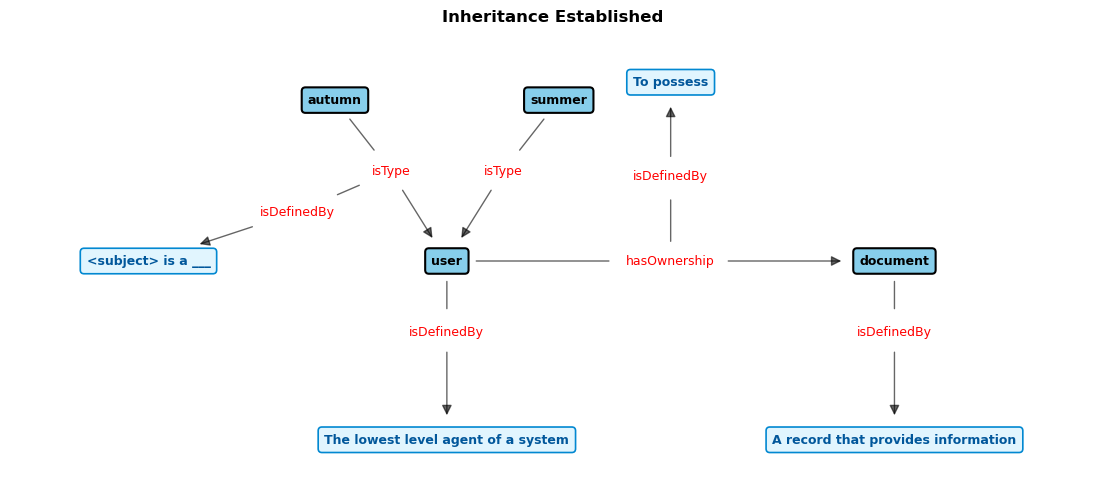

In [356]:
builder = StructuredGraphBuilder()
# Primary Entities
builder.add_entity("user", label="user", pos=(-1, 0))
builder.add_entity("document", label="document", pos=(2, 0))
builder.add_entity("autumn", label="autumn", pos=(-1.75, 1.8))
builder.add_entity("summer", label="summer", pos=(-0.25, 1.8))
# Edges
builder.add_property(target_node_id="user", prop_name="isDefinedBy", prop_value="The lowest level agent of a system", prop_pos=(-1, -0.8), val_pos=(-1, -2))
builder.add_property(target_node_id="document", prop_name="isDefinedBy", prop_value="A record that provides information", prop_pos=(2, -0.8), val_pos=(2, -2))
# Main Reified Edge (Store returned relation ID)
hasOwnership_rel_id = builder.add_reified_edge(source="user", rel_name="hasOwnership", target="document", rel_pos=(0.5, 0),)
type_rel_id = builder.add_reified_edge(source="autumn", rel_name="isType", target="user", rel_pos=(-2.75/2, 1),)
_type_rel_id = builder.add_reified_edge(source="summer", rel_name="isType", target="user", rel_pos=(-1.25/2, 1),)
# Main Reified Edge Property
builder.add_property(target_node_id=hasOwnership_rel_id,prop_name="isDefinedBy",prop_value="To possess",prop_pos=(0.5, 0.95),val_pos=(0.5, 2))
builder.add_property(target_node_id=type_rel_id,prop_name="isDefinedBy",prop_value="<subject> is a ___",prop_pos=(-2, 0.55),val_pos=(-3, 0))

builder.draw('Inheritance Established', figsize=(14, 6))

In [357]:
new_df = pd.DataFrame({'object': ['isType'], 
'definition': ['<subject> is a ___'],
'semantic_uuid': [uuid6.uuid7()]})
df = pd.concat([df, new_df], ignore_index=True)
df[['object', 'semantic_uuid']].head(10)


,object,semantic_uuid
0,user,01a05512-c62c-741c-ba44-4dca7b493a5b
1,document,01a05512-c62d-7697-815c-5fbd1a5f8955
2,hasOwnership,01a05512-c62e-784a-aac5-85651317b71d
3,isType,01a05512-c6fd-7375-aadc-9812edaea3cb


In [358]:
df[['definition', 'semantic_uuid']].head(10)

,definition,semantic_uuid
0,The lowest level agent of a system,01a05512-c62c-741c-ba44-4dca7b493a5b
1,A record that provides information,01a05512-c62d-7697-815c-5fbd1a5f8955
2,To possess,01a05512-c62e-784a-aac5-85651317b71d
3,<subject> is a ___,01a05512-c6fd-7375-aadc-9812edaea3cb


In [359]:
G, pos = builder.return_graph()


In [360]:
def extract_sematic_relationships(G):
    canon_nodes = []
    triples = []
    for n in G.nodes():
        if '_' not in n:
            canon_nodes.append(n)
            continue
        text = n.split("_")
        if len(text) == 3:
            print(text)
            if text[0] in canon_nodes and text[2] in canon_nodes: 
                triples.append(text)
    return canon_nodes, triples

canon_nodes, triples = extract_sematic_relationships(G)
    

['user', 'isDefinedBy', 'The lowest level agent of a system']
['document', 'isDefinedBy', 'A record that provides information']
['user', 'hasOwnership', 'document']
['autumn', 'isType', 'user']
['summer', 'isType', 'user']


In [361]:
relational = {key: list(val) for key, val in zip(['subject', 'predicate', 'object'], zip(*triples))}

df2 = pd.DataFrame.from_dict(relational)
df2.head()

,subject,predicate,object
0,user,hasOwnership,document
1,autumn,isType,user
2,summer,isType,user


What needs to be hashed? All of the unique values of the triple, for each timestamp 

In [362]:
unique_series = dict(object=list(set(df2.values.ravel())))
df3 = pd.DataFrame.from_dict(unique_series)
df3['uri'] = [uuid6.uuid7() for _ in range(len(df3))]
df3.head(7)


,object,uri
0,summer,01a05512-c720-7a0f-bf83-c92f851ba56f
1,document,01a05512-c721-7bf9-aaee-e736b89c7019
2,autumn,01a05512-c722-74ea-a95b-2a51d2e2bbee
3,isType,01a05512-c723-73c1-bd62-d4ad06b8980a
4,user,01a05512-c724-721c-8cc9-37edf593d471
5,hasOwnership,01a05512-c725-7cca-8bdc-25a6a92b1318


In [363]:
df4 = pd.merge(df, df3, how='outer', on='object')
df4.head(7)

,object,definition,semantic_uuid,uri
0,autumn,NaN,NaN,01a05512-c722-74ea-a95b-2a51d2e2bbee
1,document,A record that provides information,01a05512-c62d-7697-815c-5fbd1a5f8955,01a05512-c721-7bf9-aaee-e736b89c7019
2,hasOwnership,To possess,01a05512-c62e-784a-aac5-85651317b71d,01a05512-c725-7cca-8bdc-25a6a92b1318
3,isType,<subject> is a ___,01a05512-c6fd-7375-aadc-9812edaea3cb,01a05512-c723-73c1-bd62-d4ad06b8980a
4,summer,NaN,NaN,01a05512-c720-7a0f-bf83-c92f851ba56f
5,user,The lowest level agent of a system,01a05512-c62c-741c-ba44-4dca7b493a5b,01a05512-c724-721c-8cc9-37edf593d471


### Lemma: 

Let nodes be defined as the set of all subjects and objects. Semantic and object uuids are bijective if and only if all nodes are required to have a unique defintion. Therefore, only one uuid is required. 

#### Proof:

Let $S$ and $O$ be the set of sematic and object uuids. Object uuids are defined by a unique identifier for each node: $o_n \in O$ Semantic uuids are defined by a unique definition $s_d \in S$. 

($\Longrightarrow$) Given that $f:S \mapsto O$ is bijective, then for every $s_d \in S \ \exists \ o_n \in O: f(s_d)=o_n$ Additionally, $f(s_n) = f(s_m) \Rightarrow s_n = s_m$, and given there must exist an inverse function $g: O \mapsto S$ where $f(s_d)=o_n \Rightarrow g(o_n) = s_d$. Since $g(o_n) = g(o_m) \Rightarrow o_n = o_m$, this demonstrates that every object $o_n$ 1. maps to a unique $s_d$, and 2. $|S| = |O|$

($\Longleftarrow$) Given that all nodes have a unique defintion, then for every $o_n \in O \ \exists \ s_d \in S: g(o_n)=s_d$. Additionally, $g(o_n) = g(o_m) \Rightarrow o_n = o_m$. By the same logic, there must exist an inverse function $f: S \mapsto O$, demonstrating bijectivity analagously. 

## However: 

If it is NOT true that every unique object has a unique definiton, then necessarily, definitions have a surjective (one-to-many) relationship. If that is true, then the datatable above demonstrates a mapping problem that requires a taxomy-allocation-ledger to ensure that all objects that are a part of a one-to-many for \<isDefinedBy\> inherit that definition from a defined parent class through the \<isType\> relation. The enforcement of those conditions require the existance of object uuid to ensure spatiotemporal purity. 

In [364]:
df5_1 = pd.merge(df2[['subject', 'object']], df4[['object', 'uri']], how='left', on='object')
df5_2 = pd.merge(df2[['subject', 'object']], df4[['object', 'uri']].rename(columns={"object": "subject", "uri":"uri_subject"}), how='left', on='subject')
df6 = df5_1.assign(uri_subject=df5_2["uri_subject"])
df6


,subject,object,uri,uri_subject
0,user,document,01a05512-c721-7bf9-aaee-e736b89c7019,01a05512-c724-721c-8cc9-37edf593d471
1,autumn,user,01a05512-c724-721c-8cc9-37edf593d471,01a05512-c722-74ea-a95b-2a51d2e2bbee
2,summer,user,01a05512-c724-721c-8cc9-37edf593d471,01a05512-c720-7a0f-bf83-c92f851ba56f


In [365]:
df6[['uri', 'uri_subject']]

,uri,uri_subject
0,01a05512-c721-7bf9-aaee-e736b89c7019,01a05512-c724-721c-8cc9-37edf593d471
1,01a05512-c724-721c-8cc9-37edf593d471,01a05512-c722-74ea-a95b-2a51d2e2bbee
2,01a05512-c724-721c-8cc9-37edf593d471,01a05512-c720-7a0f-bf83-c92f851ba56f


In [366]:
rdf_terminology = {
    'classes': {
        'Literal': f'the class of literals e.g. {['string', 'int', 'float', 'bool', 'categorical_type', '...']}',
        'Property': 'the class of properties',
        'Statement': 'the class of statements (RDF triples)',
        'List': {
            'nil': 'an instance of rdf:List representing the empty list',
            'first': 'the first item in the subject RDF list',
            'rest': 'the rest of the subject RDF list after rdf:first',
            },
        'Resource': 'the class resource, everything',
        'Class': 'the class of classes',
        'Datatype': 'the class of RDF datatypes',
        'Container': {
            'Alt': 'containers of alternatives', 
            'Bag': 'unordered containers', 
            'Seq': 'ordered containers', 
            },
        'ContainerMembershipProperty': 'the class of container membership properties, rdf:_1, rdf:_2, ..., all of which are sub-properties of rdfs:member',
        },
    'properties': {
        'type': 'an instance of rdf:Property used to state that a resource is an instance of a class',
        'first': 'the first item in the subject RDF list',
        'rest': 'the rest of the subject RDF list after rdf:first',
        'value': 'idiomatic property used for structured values',
        'subject': 'the subject of the RDF statement',
        'predicate': 'the predicate of the RDF statement',
        'object': 'the object of the RDF statement',
        'subClassOf': 'the subject is a subclass of a class',
        'subPropertyOf': 'the subject is a subproperty of a property',
        'domain': 'a domain of the subject property',
        'range': 'a range of the subject property',
        'label': 'a human-readable name for the subject',
        'comment': 'a description of the subject resource',
        'member': 'a member of the subject resource',
        'seeAlso': 'further information about the subject resource',
        'isDefinedBy': 'the definition of the subject resource',
    },
}

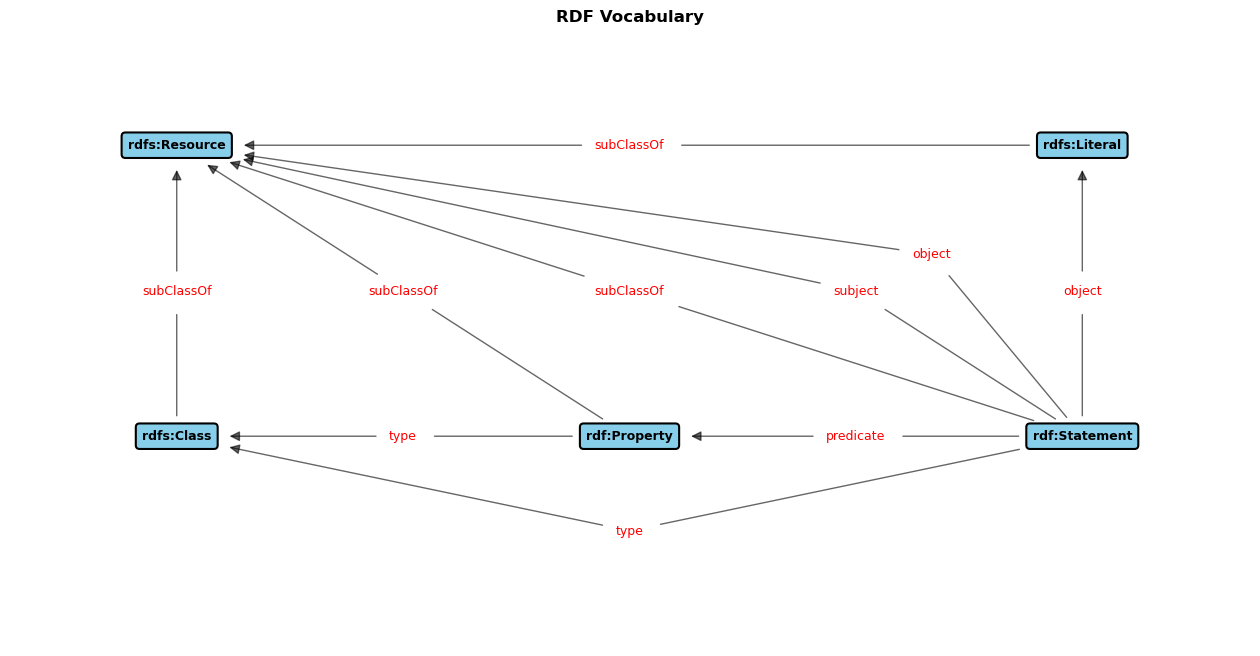

In [367]:
builder = StructuredGraphBuilder()

# Core RDF Classes
builder.add_entity( "Resource", label="rdfs:Resource", pos=(0, 3) )
builder.add_entity( "Class", label="rdfs:Class", pos=(0, 1) )
builder.add_entity( "Property", label="rdf:Property", pos=(3, 1) )
builder.add_entity( "Statement", label="rdf:Statement", pos=(6, 1) )
builder.add_entity( "Literal", label="rdfs:Literal", pos=(6, 3) )

# Class Relationships
builder.add_reified_edge( source="Class", rel_name="subClassOf", target="Resource", rel_pos=(0, 2) )
builder.add_reified_edge( source="Property", rel_name="subClassOf", target="Resource", rel_pos=(1.5, 2) )
builder.add_reified_edge( source="Statement", rel_name="subClassOf", target="Resource", rel_pos=(3, 2) )
builder.add_reified_edge( source="Literal", rel_name="subClassOf", target="Resource", rel_pos=(3, 3) )

# rdf:type relationships
property_type_rel = builder.add_reified_edge( source="Property", rel_name="type", target="Class", rel_pos=(1.5, 1) )
statement_type_rel = builder.add_reified_edge( source="Statement", rel_name="type", target="Class", rel_pos=(3, 0.35) )

# Statement Structure
builder.add_reified_edge( source="Statement", rel_name="subject", target="Resource", rel_pos=(4.5, 2) )
builder.add_reified_edge( source="Statement", rel_name="predicate", target="Property", rel_pos=(4.5, 1) )
builder.add_reified_edge( source="Statement", rel_name="object", target="Resource", rel_pos=(5, 2.25) )
builder.add_reified_edge( source="Statement", rel_name="object", target="Literal", rel_pos=(6, 2) )

# Draw
builder.draw(title="RDF Vocabulary", figsize=(16, 8), x_margin=0.75, y_margin=0.75 )

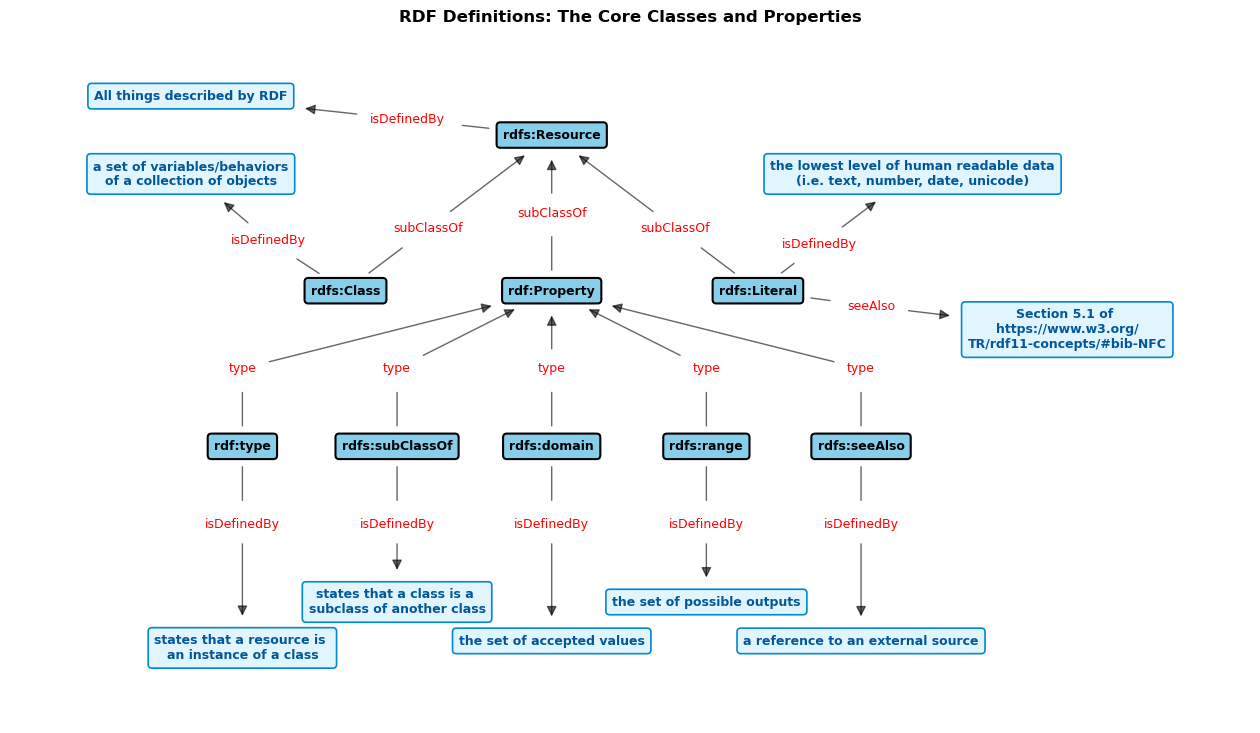

In [368]:
builder = StructuredGraphBuilder()


# Resources / Classes
builder.add_entity( "Resource", label="rdfs:Resource", pos=(3, 4))
builder.add_entity( "Class", label="rdfs:Class", pos=(1, 2))
builder.add_entity( "Property", label="rdf:Property", pos=(3, 2))
builder.add_entity( "Literal", label="rdfs:Literal", pos=(5, 2))
# rdf:type and rdfs:subClassOf as resource
builder.add_entity( "type", label="rdf:type", pos=(0, 0))
builder.add_entity( "subClassOf", label="rdfs:subClassOf", pos=(1.5, 0))
builder.add_entity( "domain", label="rdfs:domain", pos=(3, 0))
builder.add_entity( "range", label="rdfs:range", pos=(4.5, 0))
builder.add_entity( "seeAlso", label="rdfs:seeAlso", pos=(6, 0))

# Class hierarchy
builder.add_reified_edge( source="Class", rel_name="subClassOf", target="Resource",)
builder.add_reified_edge( source="Property", rel_name="subClassOf", target="Resource", rel_pos=(3, 3))
builder.add_reified_edge( source="Literal", rel_name="subClassOf", target="Resource",) 

# rdf:type relationships
builder.add_reified_edge( source="type", rel_name="type", target="Property", rel_pos=(0, 1))
builder.add_reified_edge( source="subClassOf", rel_name="type", target="Property", rel_pos=(1.5, 1))
builder.add_reified_edge( source="domain", rel_name="type", target="Property", rel_pos=(3, 1))
builder.add_reified_edge( source="range", rel_name="type", target="Property", rel_pos=(4.5, 1))
builder.add_reified_edge( source="seeAlso", rel_name="type", target="Property", rel_pos=(6, 1))

# Property definitions
builder.add_property( target_node_id="type", prop_name="isDefinedBy", prop_value="states that a resource is \nan instance of a class", prop_pos=(0, -1), val_pos=(0, -2.59))
builder.add_property( target_node_id="subClassOf", prop_name="isDefinedBy", prop_value="states that a class is a \nsubclass of another class", prop_pos=(1.5, -1), val_pos=(1.5, -2))
builder.add_property( target_node_id="domain", prop_name="isDefinedBy", prop_value="the set of accepted values", prop_pos=(3, -1), val_pos=(3, -2.5))
builder.add_property( target_node_id="range", prop_name="isDefinedBy", prop_value="the set of possible outputs", prop_pos=(4.5, -1), val_pos=(4.5, -2))
builder.add_property( target_node_id="seeAlso", prop_name="isDefinedBy", prop_value="a reference to an external source", prop_pos=(6, -1), val_pos=(6, -2.5))
builder.add_property( target_node_id="Class", prop_name="isDefinedBy", prop_value="a set of variables/behaviors\nof a collection of objects", prop_pos=(0.25, 2.65),val_pos=(-0.5, 3.5))
builder.add_property( target_node_id="Literal", prop_name="isDefinedBy", prop_value="the lowest level of human readable data\n(i.e. text, number, date, unicode)",val_pos=(6.5, 3.5))
builder.add_property( target_node_id="Literal", prop_name="seeAlso", prop_value="Section 5.1 of \nhttps://www.w3.org/\nTR/rdf11-concepts/#bib-NFC",val_pos=(8, 1.5),prop_pos=(6.1, 1.8))
builder.add_property( target_node_id="Resource", prop_name="isDefinedBy", prop_value="All things described by RDF",val_pos=(-0.5, 4.5),)

builder.draw(title="RDF Definitions: The Core Classes and Properties", figsize=(16, 9), x_margin=0.75, y_margin=0.75 )

In [369]:
builder.get_triples()

[('Resource', 'isDefinedBy', 'All things described by RDF'),
 ('Class', 'subClassOf', 'Resource'),
 ('Class',
  'isDefinedBy',
  'a set of variables/behaviors\nof a collection of objects'),
 ('Property', 'subClassOf', 'Resource'),
 ('Literal', 'subClassOf', 'Resource'),
 ('Literal',
  'isDefinedBy',
  'the lowest level of human readable data\n(i.e. text, number, date, unicode)'),
 ('Literal',
  'seeAlso',
  'Section 5.1 of \nhttps://www.w3.org/\nTR/rdf11-concepts/#bib-NFC'),
 ('type', 'type', 'Property'),
 ('type', 'isDefinedBy', 'states that a resource is \nan instance of a class'),
 ('subClassOf', 'type', 'Property'),
 ('subClassOf',
  'isDefinedBy',
  'states that a class is a \nsubclass of another class'),
 ('domain', 'type', 'Property'),
 ('domain', 'isDefinedBy', 'the set of accepted values'),
 ('range', 'type', 'Property'),
 ('range', 'isDefinedBy', 'the set of possible outputs'),
 ('seeAlso', 'type', 'Property'),
 ('seeAlso', 'isDefinedBy', 'a reference to an external source')]